## Model A, version 2 — high-risk detection

**0 = Not high risk** (Healthy + Low Risk), **1 = High Risk/Injured**. Missing a positive case matters more than a false alarm, so tune by F2. Compare **with and without sport** on the same athlete split.

This exploratory revision follows inspection of the three-class results; the reused test set is not a fresh confirmation set. Labels still mix risk and actual injury.

### 3.1 Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, fbeta_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import (train_test_split, StratifiedGroupKFold,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
SPORTS = ['Football', 'Basketball', 'Track']
TARGET = 'injury_occurred'
LABELS = ['Not high risk', 'High Risk/Injured']
SURFACES = {0: 'Grass', 1: 'Turf', 2: 'Indoor', 3: 'Track', 4: 'Other'}
FEATURE_SETS = {'Without sport': False, 'With sport': True}

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)

### 3.2 Load and define the binary target

In [3]:
df = pd.read_csv('multimodal_sports_injury_dataset.csv')
for col in ['sport_type', 'gender']:
    df[col] = df[col].astype('string').str.strip()
df['sport_type'] = df['sport_type'].replace({'Soccer': 'Football'})
df = df.loc[df['sport_type'].isin(SPORTS)].copy()
assert df[TARGET].isin([0, 1, 2]).all(), 'Unknown or missing source target.'
df['playing_surface'] = df['playing_surface'].map(SURFACES).astype('category')
df['gender'] = df['gender'].astype('category')

# Preserve original labels; the comparison changes only the model target.
y = df[TARGET].eq(2).astype(int).rename('high_risk')
X = df.drop(columns=['athlete_id', 'session_id', TARGET])
print(f'{len(df):,} sessions from {df.athlete_id.nunique()} athletes')

13,043 sessions from 132 athletes


### 3.3 Same athlete-level split as version 1

Hold out 20% of athletes within each sport.

In [4]:
athletes = df[['athlete_id', 'sport_type']].drop_duplicates().sort_values('athlete_id')
train_ids, test_ids = [], []
for sport in SPORTS:
    ids = athletes.loc[athletes['sport_type'].eq(sport), 'athlete_id']
    # Split athlete IDs, not individual sessions.
    train_part, test_part = train_test_split(ids, test_size=0.20, random_state=SEED)
    train_ids.extend(train_part)
    test_ids.extend(test_part)
assert set(train_ids).isdisjoint(test_ids), 'An athlete appears on both sides.'

train_mask = df['athlete_id'].isin(train_ids)
test_mask = df['athlete_id'].isin(test_ids)
X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]
groups_train = df.loc[train_mask, 'athlete_id']
display(df.assign(partition=np.where(train_mask, 'Train', 'Test')).groupby(
    ['sport_type', 'partition']
).agg(athletes=('athlete_id', 'nunique'), sessions=('athlete_id', 'size')))
print(f'Positive rate in training: {y_train.mean():.1%}')

athletes  sessions
sport_type partition                    
Basketball Test              9       890
           Train            32      3169
Football   Test             10       989
           Train            39      3848
Track      Test              9       887
           Train            33      3260

Positive rate in training: 15.1%


### 3.4 Pipelines and grouped folds

Both feature sets share preprocessing and folds. Fit category encoding only on training rows; unseen categories become all-zero blocks without dropping a reference category.

In [5]:
numeric_features = [c for c in X.columns if c not in ['playing_surface', 'gender', 'sport_type']]

def make_model(estimator, include_sport=False):
    # Toggle sport while retaining other predictors.
    categories = ['playing_surface', 'gender'] + (['sport_type'] if include_sport else [])
    preprocess = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric_features),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', drop=None)),
        ]), categories),
    ])
    # Columns not listed above are excluded, including sport in the first variant.
    return Pipeline([('preprocess', preprocess), ('model', estimator)])

# Balance labels while keeping each athlete together.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
# Reuse identical folds across all models.
folds = list(cv.split(X_train, y_train, groups=groups_train))
fold_rows = []
for fold, (fit_idx, valid_idx) in enumerate(folds, start=1):
    fit_groups = groups_train.iloc[fit_idx]
    valid_groups = groups_train.iloc[valid_idx]
    assert set(fit_groups).isdisjoint(valid_groups), 'An athlete crosses a CV fold.'
    fold_rows.append({'Fold': fold, 'Train athletes': fit_groups.nunique(),
                      'Validation athletes': valid_groups.nunique(),
                      'Validation positive rate': y_train.iloc[valid_idx].mean()})
display(pd.DataFrame(fold_rows).set_index('Fold').round(3))

,Train athletes,Validation athletes,Validation positive rate
Fold,,,
1,83,21,0.149
2,84,20,0.150
3,83,21,0.155
4,83,21,0.151
5,83,21,0.148


### 3.5 Scoring and search spaces

F2 favors recall over precision; beta=2 is a working preference, not a measured cost ratio. Also record average precision (AP), which measures ranking across thresholds.

Keep the previous search: 18 tree settings; 12 sampled forest settings with 200 trees. Select settings at the default cutoff, then select an alert threshold using grouped training predictions.

In [6]:
# Track both metrics during each search.
scoring = {'f2': make_scorer(fbeta_score, beta=2, zero_division=0),  # Wrap F2 for CV scoring.
           'ap': 'average_precision'}
tree_grid = {
    'model__max_depth': [3, 6, None],
    'model__min_samples_leaf': [5, 20, 50],
    'model__class_weight': [None, 'balanced'],
}
forest_grid = {
    'model__max_depth': [6, 12, None],
    'model__min_samples_leaf': [2, 10, 30],
    'model__max_features': ['sqrt', 0.5],
    'model__class_weight': [None, 'balanced'],
}
searches = {}

### 3.6 Decision trees — with and without sport

In [7]:
for feature_set, include_sport in FEATURE_SETS.items():
    search = GridSearchCV(
        make_model(DecisionTreeClassifier(random_state=SEED), include_sport),
        tree_grid, scoring=scoring, refit='f2', cv=folds,  # Select the model using F2.
        n_jobs=2, pre_dispatch=2, error_score='raise',
    )
    search.fit(X_train, y_train)
    searches[(feature_set, 'Decision tree')] = search
    print(feature_set, '— tree:', search.best_params_)
    print(f'CV F2 at default cutoff: {search.best_score_:.3f}')

Without sport — tree: {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 50}
CV F2 at default cutoff: 0.653
With sport — tree: {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 50}
CV F2 at default cutoff: 0.653


### 3.7 Random forests — with and without sport

In [8]:
for feature_set, include_sport in FEATURE_SETS.items():
    search = RandomizedSearchCV(
        make_model(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
                   include_sport),
        forest_grid, n_iter=12, random_state=SEED, scoring=scoring, refit='f2', cv=folds,  # Select the model using F2.
        n_jobs=2, pre_dispatch=2, error_score='raise',
    )
    search.fit(X_train, y_train)
    searches[(feature_set, 'Random forest')] = search
    print(feature_set, '— forest:', search.best_params_)
    print(f'CV F2 at default cutoff: {search.best_score_:.3f}')

Without sport — forest: {'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 6, 'model__class_weight': 'balanced'}
CV F2 at default cutoff: 0.700
With sport — forest: {'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 6, 'model__class_weight': 'balanced'}
CV F2 at default cutoff: 0.696


### 3.8 Choose alert thresholds on training data

For each selected pipeline, generate probabilities for athletes excluded from that fold's fit. Try cutoffs from 0.05 to 0.95 and maximize pooled F2; ties favor a higher cutoff. Freeze these thresholds before testing.

Hyperparameters and cutoffs reuse these folds, so the selection scores are optimistic, not a separate validation estimate. This two-stage search is not a joint optimum. Model scores are not clinically calibrated probabilities.

In [8]:
models, thresholds = {}, {}
threshold_tables = {}
selection_rows = []
# Search cutoffs using training predictions only.
cutoffs = np.round(np.linspace(0.05, 0.95, 19), 2)
for key, search in searches.items():
    # Predict each athlete without training on them.
    oof_prob = cross_val_predict(
        search.best_estimator_, X_train, y_train, cv=folds,
        method='predict_proba', n_jobs=2, pre_dispatch=2,  # Return class probabilities, not labels.
    )[:, 1]  # Select probabilities for the high-risk class.
    candidates = []
    for cutoff in cutoffs:
        # Convert scores into alerts using this cutoff.
        predicted = (oof_prob > cutoff).astype(int)
        candidates.append({'Threshold': cutoff,
                           'F2': fbeta_score(y_train, predicted, beta=2, zero_division=0),
                           'Recall': recall_score(y_train, predicted, zero_division=0),
                           'Precision': precision_score(y_train, predicted, zero_division=0)})
    # Break equal-score ties with higher cutoffs.
    table = pd.DataFrame(candidates).sort_values(['F2', 'Threshold'], ascending=False)
    chosen = table.iloc[0]
    models[key] = search.best_estimator_  # Already refitted on all training athletes.
    thresholds[key] = chosen['Threshold']
    threshold_tables[key] = table
    selection_rows.append({'Feature set': key[0], 'Model': key[1],
                           'CV F2 at 0.5': search.best_score_,
                           'CV std': search.cv_results_['std_test_f2'][search.best_index_],
                           'OOF AP': average_precision_score(y_train, oof_prob),
                           'Threshold': chosen['Threshold'], 'OOF selected F2': chosen['F2']})
selection = pd.DataFrame(selection_rows).set_index(['Feature set', 'Model']).sort_index()
display(selection.round(3))

CV F2 at 0.5  CV std  OOF AP  Threshold  \
Feature set   Model                                                    
With sport    Decision tree         0.653   0.018   0.474       0.35   
              Random forest         0.692   0.014   0.536       0.45   
Without sport Decision tree         0.653   0.018   0.474       0.35   
              Random forest         0.692   0.012   0.538       0.45   

                             OOF selected F2  
Feature set   Model                           
With sport    Decision tree            0.658  
              Random forest            0.694  
Without sport Decision tree            0.658  
              Random forest            0.698

### 3.9 Dummy references

“Never alert” shows the high-accuracy trap. “Always alert” catches all positives but flags every negative too; learned models should offer a more useful trade-off.

In [9]:
for name, label in [('Never alert', 0), ('Always alert', 1)]:
    key = ('Baseline', name)
    # Constant ignores features and predicts one label.
    model = make_model(DummyClassifier(strategy='constant', constant=label))
    model.fit(X_train, y_train)
    models[key] = model
    thresholds[key] = 0.5

### 3.10 Frozen test evaluation

Report misses and false alarms as session counts. AP uses scores; F2, precision and recall use the selected cutoff. No settings are revised from these results.

In [10]:
def scores(actual, probability, threshold):
    # Apply the cutoff fixed before test evaluation.
    predicted = (probability > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {'F2': fbeta_score(actual, predicted, beta=2, zero_division=0),
            'Recall': recall_score(actual, predicted, zero_division=0),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'F1': f1_score(actual, predicted, zero_division=0),
            # Average precision evaluates ranking across thresholds.
            'AP': average_precision_score(actual, probability),
            'Accuracy': accuracy_score(actual, predicted),
            'False alarms': int(fp), 'Missed positives': int(fn)}

test_predictions = df.loc[test_mask, ['athlete_id', 'sport_type', TARGET]].copy()
test_predictions['high_risk'] = y_test
probabilities = {}
test_rows = []
for key, model in models.items():
    # Get positive-class scores before applying the cutoff.
    probability = model.predict_proba(X_test)[:, 1]
    probabilities[key] = probability
    name = ' | '.join(key)
    test_predictions[name] = (probability > thresholds[key]).astype(int)
    test_rows.append({'Feature set': key[0], 'Model': key[1], 'Threshold': thresholds[key],
                      **scores(y_test, probability, thresholds[key])})
test_results = pd.DataFrame(test_rows).set_index(['Feature set', 'Model']).sort_index()
display(test_results.round(3))
print(f'Test positives: {y_test.sum()} / {len(y_test)} sessions; {len(test_ids)} athletes')

Threshold     F2  Recall  Precision     F1  \
Feature set   Model                                                       
Baseline      Always alert        0.50  0.470   1.000      0.151  0.262   
              Never alert         0.50  0.000   0.000      0.000  0.000   
With sport    Decision tree       0.35  0.675   0.921      0.327  0.482   
              Random forest       0.45  0.700   0.894      0.374  0.528   
Without sport Decision tree       0.35  0.675   0.921      0.327  0.482   
              Random forest       0.45  0.700   0.894      0.375  0.528   

                                AP  Accuracy  False alarms  Missed positives  
Feature set   Model                                                           
Baseline      Always alert   0.151     0.151          2349                 0  
              Never alert    0.151     0.849             0               417  
With sport    Decision tree  0.494     0.702           792                33  
              Random forest  0.537     0.758           624                44  
Without sport Decision tree  0.494     0.702           792                33  
              Random forest  0.541     0.759           622                44

Test positives: 417 / 2766 sessions; 28 athletes


### 3.11 Does sport help?

Compare tuned pipelines on identical athletes. The difference measures the benefit of including sport under this search budget, not a causal effect.

In [11]:
metric_columns = ['F2', 'Recall', 'Precision', 'AP', 'False alarms', 'Missed positives']
# Compare matched models with and without sport.
sport_difference = (test_results.loc['With sport', metric_columns]
                    - test_results.loc['Without sport', metric_columns])
sport_difference.index.name = 'Model'
print('With sport minus without sport:')
display(sport_difference.round(3))

sport_rows = []
for sport in SPORTS:
    mask = test_predictions['sport_type'].eq(sport)
    for key in searches:
        sport_rows.append({'Sport': sport, 'Feature set': key[0], 'Model': key[1],
                           'Athletes': test_predictions.loc[mask, 'athlete_id'].nunique(),
                           **scores(y_test.loc[mask], probabilities[key][mask.to_numpy()], thresholds[key])})
sport_results = pd.DataFrame(sport_rows).set_index(['Sport', 'Feature set', 'Model'])
display(sport_results[['Athletes'] + metric_columns].round(3))

With sport minus without sport:


,F2,Recall,Precision,AP,False alarms,Missed positives
Model,,,,,,
Decision tree,0.000,0.0,0.000,0.000,0,0
Random forest,-0.001,0.0,-0.001,-0.004,2,0


Athletes     F2  Recall  Precision  \
Sport      Feature set   Model                                               
Football   Without sport Decision tree        10  0.652   0.894      0.313   
           With sport    Decision tree        10  0.652   0.894      0.313   
           Without sport Random forest        10  0.679   0.873      0.359   
           With sport    Random forest        10  0.679   0.873      0.359   
Basketball Without sport Decision tree         9  0.676   0.927      0.325   
           With sport    Decision tree         9  0.676   0.927      0.325   
           Without sport Random forest         9  0.692   0.879      0.373   
           With sport    Random forest         9  0.691   0.879      0.372   
Track      Without sport Decision tree         9  0.696   0.940      0.341   
           With sport    Decision tree         9  0.696   0.940      0.341   
           Without sport Random forest         9  0.728   0.927      0.391   
           With sport    Random forest         9  0.727   0.927      0.390   

                                           AP  False alarms  Missed positives  
Sport      Feature set   Model                                                 
Football   Without sport Decision tree  0.464           279                15  
           With sport    Decision tree  0.464           279                15  
           Without sport Random forest  0.511           221                18  
           With sport    Random forest  0.513           221                18  
Basketball Without sport Decision tree  0.508           239                 9  
           With sport    Decision tree  0.508           239                 9  
           Without sport Random forest  0.546           183                15  
           With sport    Random forest  0.534           184                15  
Track      Without sport Decision tree  0.519           274                 9  
           With sport    Decision tree  0.519           274                 9  
           Without sport Random forest  0.569           218                11  
           With sport    Random forest  0.567           219                11

### 3.12 Errors and precision–recall curves

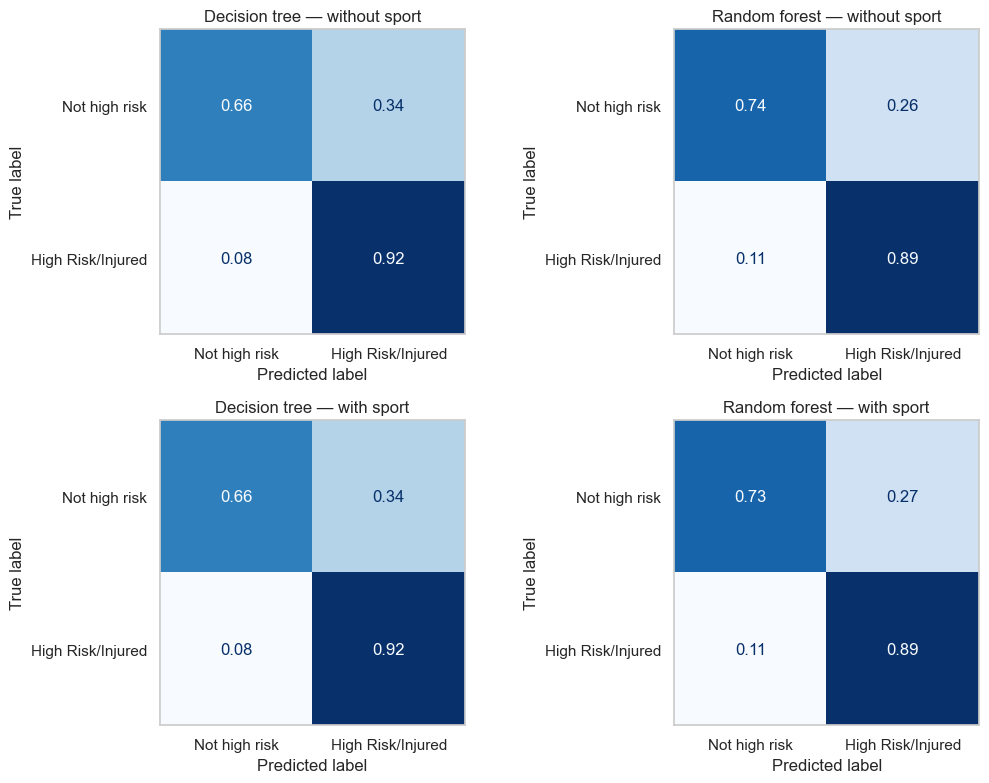

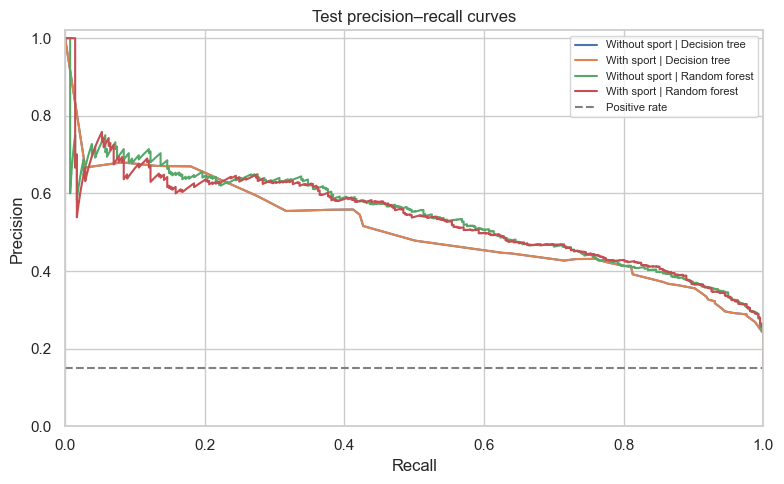

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, feature_set in enumerate(FEATURE_SETS):
    for col, name in enumerate(['Decision tree', 'Random forest']):
        key = (feature_set, name)
        predicted = (probabilities[key] > thresholds[key]).astype(int)
        ax = axes[row, col]
        ConfusionMatrixDisplay.from_predictions(
            y_test, predicted, labels=[0, 1], display_labels=LABELS,
            # Show proportions within each actual class.
            normalize='true', values_format='.2f', cmap='Blues', colorbar=False, ax=ax,
        )
        ax.set_title(f'{name} — {feature_set.lower()}')
        ax.grid(False)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for key in searches:
    # Trace precision and recall across score cutoffs.
    precision, recall, _ = precision_recall_curve(y_test, probabilities[key])
    ax.plot(recall, precision, label=' | '.join(key))
ax.axhline(y_test.mean(), color='grey', linestyle='--', label='Positive rate')
ax.set(xlabel='Recall', ylabel='Precision', title='Test precision–recall curves',
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Interpretation

- **With sport:** forest F2 **0.700**, recall **0.894**, precision **0.374** at cutoff **0.45**: 44 missed positives and 624 false alarms.
- The tree catches more positives (recall **0.921**, 33 misses) but produces 792 false alarms; F2 is **0.675**.
- Sport adds little on this split: tree predictions are identical; forest AP is **0.537 with sport** versus **0.541 without**. This does not establish equivalence across populations.
- Always alert achieves recall 1 but 2,349 false alarms, showing why recall alone is insufficient.

Keep all settings frozen. The binary target and reused test set make this an exploratory revision, not a fresh confirmation or a direct score comparison with the three-class task. No files or figures are exported.